# 04 · OCR quality under scanning conditions

**Question.** How accurate is Tesseract's LSTM English model on printed pages under typical degradations, and what OCR-confidence level should trigger S-Way's "review the text" warning?

**Engine note.** The browser uses Tesseract 5 compiled to WebAssembly (tesseract.js-core 7) with the `best_int` English model. This notebook uses the native Tesseract 5 command-line engine through `pytesseract` with its installed English model, so absolute numbers can differ slightly from the browser build.

**Metric.** Character error rate (CER) and word error rate (WER) = Levenshtein edit distance / reference length.

In [1]:
import sys, json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
sys.path.insert(0, '.')
from sway_research import *
RESULTS = DATA / 'results'; RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 90, 'font.family': 'monospace', 'axes.facecolor': '#EDE3CC', 'figure.facecolor': '#F4ECD9'})
pd.set_option('display.width', 140)

In [2]:
import pytesseract, shutil
from PIL import ImageFont
from rapidfuzz.distance import Levenshtein
print('Tesseract', pytesseract.get_tesseract_version())
font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSerif.ttf', 26)
rng = random.Random(4)
books = sorted(p.name for p in GUT.glob('*.txt') if 'bible' not in p.name and 'blake' not in p.name)
def render(text, path, kind):
    img = Image.new('L', (1240, 1000), 250); d = ImageDraw.Draw(img); y = 80
    for line in textwrap_lines(text, 68):
        d.text((90, y), line, font=font, fill=25); y += 40
    degrade_image(img, kind, rng).save(path)
def textwrap_lines(text, width):
    import textwrap; return textwrap.wrap(text, width)
def ocr_conf(path):
    d = pytesseract.image_to_data(Image.open(path), lang='eng', output_type=pytesseract.Output.DATAFRAME)
    d = d[d.conf >= 0]; txt = ' '.join(str(t) for t in d.text if str(t).strip() and str(t) != 'nan')
    return txt, float(d.conf.mean()) if len(d) else 0.0
rows = []
for i in range(10):
    b = rng.choice(books); ss = sentences(load_book(b)); ref = ' '.join(passage(ss, rng.randrange(0, len(ss) - 100), 140))
    for kind in [None, 'noise', 'blur', 'rotate', 'lowres', 'jpeg']:
        pth = WORK / f'ocr_{i}_{kind}.png'; render(ref, pth, kind)
        hyp, conf = ocr_conf(pth)
        norm = lambda s: ' '.join(s.split())
        rows.append(dict(page=i, degradation=kind or 'clean', confidence=conf,
                         cer=Levenshtein.distance(norm(ref), norm(hyp)) / len(norm(ref)),
                         wer=Levenshtein.distance(norm(ref).split(), norm(hyp).split()) / len(norm(ref).split())))
R = pd.DataFrame(rows)
R.groupby('degradation')[['confidence', 'cer', 'wer']].mean().round(3)

Tesseract 5.3.4


,confidence,cer,wer
degradation,,,
blur,95.243,0.006,0.031
clean,95.707,0.002,0.009
jpeg,95.800,0.000,0.002
lowres,95.414,0.002,0.008
noise,95.552,0.013,0.024
rotate,95.292,0.003,0.014


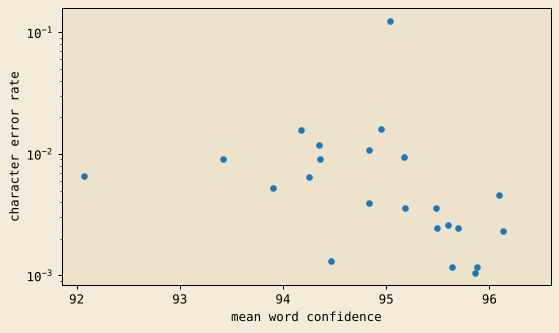

CER when confidence < 70: no pages | ≥ 70: 0.004


In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(R.confidence, R.cer, s=18)
ax.set_xlabel('mean word confidence'); ax.set_ylabel('character error rate'); ax.set_yscale('log'); plt.show()
print('CER when confidence < 70:', R[R.confidence < 70].cer.mean().round(3) if (R.confidence < 70).any() else 'no pages', '| ≥ 70:', R[R.confidence >= 70].cer.mean().round(3))

## Handwriting

Running the print-trained model on the synthetic handwriting pages illustrates why S-Way warns that handwriting OCR is unreliable and offers manual correction. (The synthetic "letters" are not real words, so only the confidence is meaningful here.)

In [4]:
hw = sorted(WORK.glob('hw_w0*_s0.png'))[:5]
pd.DataFrame([dict(page=p.name, confidence=round(ocr_conf(p)[1], 1)) for p in hw])

,page,confidence
0,hw_w00_s0.png,42.9
1,hw_w01_s0.png,40.6
2,hw_w02_s0.png,45.4
3,hw_w03_s0.png,29.5
4,hw_w04_s0.png,43.3


In [5]:
out = {'ocr': {'warn_below_confidence': 70}, 'metrics': R.groupby('degradation')[['confidence', 'cer', 'wer']].mean().round(4).to_dict()}
(RESULTS / 'ocr.json').write_text(json.dumps(out, indent=2)); out['metrics']

{'confidence': {'blur': 95.2427,
  'clean': 95.7065,
  'jpeg': 95.8,
  'lowres': 95.4142,
  'noise': 95.5522,
  'rotate': 95.2924},
 'cer': {'blur': 0.0058,
  'clean': 0.002,
  'jpeg': 0.0004,
  'lowres': 0.0015,
  'noise': 0.0133,
  'rotate': 0.0026},
 'wer': {'blur': 0.0311,
  'clean': 0.0089,
  'jpeg': 0.002,
  'lowres': 0.008,
  'noise': 0.0245,
  'rotate': 0.014}}